In [43]:
import pandas as pd
import numpy as np
from scipy.io import loadmat
import os
os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
import keras
from keras import layers, Model
from sklearn.model_selection import train_test_split
from keras.optimizers import Adam, RMSprop
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy="median")
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import cross_val_score
from sklearn.metrics import make_scorer, mean_squared_error
from scikeras.wrappers import KerasRegressor
from sklearn.model_selection import GridSearchCV
from joblib import dump, load
from scipy.signal import savgol_filter, welch, butter, filtfilt
from scipy.ndimage import gaussian_filter
from numpy import cos, sin
import joblib

In [15]:
def def_parametros(tipo_dados):
    if tipo_dados == 'completo':
        parametros = [
            "TIME",        "TEMPO_SAD",        "EVENTO",        "HH",        "MM",        "SS",        "MSS",        "TOT",        "ALFAG",        "BETAG",
            "DL",        "DM",        "DN",        "DF",        "NX",        "NY",        "NZ",        "P",        "Q",        "R",        "PB",        "PB1",
            "QB",        "QB1",        "TI",        "T5_C",        "TETAL",        "FIL",        "CID",        "NG",        "PSI",        "PBEX",        "PIX",
            "PIY",        "VB",        "VB1",        "ZPB",        "ZPB1",        "W",        "pa",        "qc",        "Zp",        "Vc",        "Mach",
            "Ta_C",        "Va",        "Alfa",        "Beta",        "Ta_K",        "T",        "No. OBS."
    ]
    else:
        parametros = [
            "TEMPO_SAD", "NG", "W", "Zp", "Mach", "Va", "Ta_C", "CL", "CD", "Ta_K", "T", "No. OBS."
        ]
    return parametros

In [16]:
def butter_lowpass(signal, cutoff_period_s, fs=1.0, order=1):
    cutoff_freq = 1.0 / cutoff_period_s
    nyq = 0.5 * fs
    normal_cutoff = cutoff_freq / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return filtfilt(b, a, signal)

In [17]:
def parametros_adicionais(df, tipo_dados):
    Ta0 = 288.15
    df['theta'] = df['Ta_K']/Ta0

    df['Z'] = 0.3048*df['Zp'] # Altitude em metros
    df['a1'] = df['Z']<=11000
    df['a2'] = df['Z']>11000

    df['pa'] = (1013.25*(1-6.87559e-6*df['Zp'])**(5.25611))*(df['a1'])+(226.306*np.exp(157.696e-6 *(11000-df['Z'])))*(df['a2']) # Pressao em mbar
    df['Rho'] = df['pa']/(2.869*(df['Ta_K'])) # Densidade em kg/m³

    Pa0 = 1013.25
    df['delta'] = df['pa']/Pa0
    
    df['N1_over_sqrt_theta'] = df['NG']/np.sqrt(df['theta'])

    S = 19.3
    if tipo_dados == 'completo':
        # df['Zp_teste'] = (1 - (df['pa']/1013.25)**0.190255)/6.87535e-6 # Bastante parecidos com Zp e Mach
        # df['Mach_teste'] = np.sqrt(5*(((df['qc']/df['pa'])+1)**(2/7)-1))
        df['NX_filtered'] = butter_lowpass(df['NX'], cutoff_period_s=15)
        df['NZ_filtered'] = butter_lowpass(df['NZ'], cutoff_period_s=15)
        df['Alfa_filtered'] = butter_lowpass(df['Alfa'], cutoff_period_s=30)
        df['Va_filtered'] = butter_lowpass(df['Va'], cutoff_period_s=30)
        df['Hdot'] = (df['NX_filtered']*np.cos(np.radians(df['Alfa_filtered'])) - df['NZ_filtered']*np.sin(np.radians(df['Alfa_filtered'])))*df['Va_filtered'] # Hdot em m/s
        df['Hdot_V'] = (df['NX_filtered']*np.cos(np.radians(df['Alfa_filtered'])) - df['NZ_filtered']*np.sin(np.radians(df['Alfa_filtered']))) # Hdot em m/s
        df['NZ_W_dlt'] = df['NZ']*df['W']/df['delta']
    else:     
        df.loc[df['h']==50, 'Zp_ref'] = df.loc[df['h']==50, 'Zp'].mean()
        df.loc[df['h']==150, 'Zp_ref'] = df.loc[df['h']==150, 'Zp'].mean()
        df.loc[df['h']==300, 'Zp_ref'] = df.loc[df['h']==300, 'Zp'].mean()
        df.loc[df['h']==400, 'Zp_ref'] = df.loc[df['h']==400, 'Zp'].mean()

        df['deltaZ'] = (df['Zp'] - df['Zp_ref'])*df['theta'] * 0.3048 # Diferença de altitude corrigida para a temperatura, convertendo para metros
        df['Va_ms'] = df['Va']*0.5144 # Convertendo Va de kt para m/s
        df['Vcorr'] = np.sqrt(df['Va_ms']**2 + 2*9.81*df['deltaZ']) # Corrigindo Va para o efeito da altitude, convertendo para m/s
        
        n = 3001
        grau = 2
        T = df['TEMPO_SAD'].diff().mean()
        df['Vdot'] = (
            df.groupby('h')['Vcorr']
            .transform(lambda x: savgol_filter(x, window_length=n, polyorder=grau, deriv=1, delta=T))
        )
        g = 9.81 # Aceleração da gravidade em m/s²
        df['Hdot'] = df['Vcorr'] * df['Vdot'] / g

        df['T_over_delta'] = (df['T']*4.44822)/df['delta']

        df['D'] = df['Rho']*(df['Va']*0.5144)**2*S*df['CD']/2 # Arrasto em Newtons
        df['D_over_delta'] = df['D']/df['delta']

    return df

In [18]:
def make_df(tipo_dados):
    if tipo_dados == 'completo':
        files = ['039_2013_VIN_FND', '040_2013_ASO_VTO', '041_2013_GEO_AIR', '042_2013_VAU_FTR']
        # files = ['039_2013_VIN_FND']
        local = 'C:\\Users\\ymarc\\Documents\\PMG\\Dados_AT26_VoosCompletos\\'
        parametros = def_parametros(tipo_dados)
        all_dfs = []
        for file in files:
            data = loadmat(local + file + '.mat')
            df = pd.DataFrame(data['DADOS'])
            df.columns = parametros
            df['filename'] = file
            all_dfs.append(df)
        df = pd.concat(all_dfs, ignore_index=True)
    else:
        files = ['050', '150', '300', '400']
        # files = ['050']
        local = 'C:\\Users\\ymarc\\Documents\\PMG\\Dados Aceleração Nivelada AT-26\\Aceleracao_FL'
        parametros = def_parametros(tipo_dados)
        all_dfs = [pd.read_excel(local + file + '.xls', skiprows=1, names=parametros) for file in files]
        for i, item in enumerate(all_dfs): item['h'] = float(files[i])
        df = pd.concat(all_dfs, ignore_index=True)

    df = parametros_adicionais(df, tipo_dados)

    df['faixa_altitude'] = None

    if tipo_dados == 'completo':
        # df.loc[df['Zp']/1000<10, 'faixa_altitude'] = 'A'
        # df.loc[(df['Zp']/1000>=10) & (df['Zp']/1000<20), 'faixa_altitude'] = 'B'
        # df.loc[(df['Zp']/1000>=20) & (df['Zp']/1000<30), 'faixa_altitude'] = 'C'
        # df.loc[df['Zp']/1000>=30, 'faixa_altitude'] = 'D'
        df.loc[df['filename'].str.contains('039'), 'faixa_altitude'] = 'A'
        df.loc[df['filename'].str.contains('040'), 'faixa_altitude'] = 'B'
        df.loc[df['filename'].str.contains('041'), 'faixa_altitude'] = 'C'
        df.loc[df['filename'].str.contains('042'), 'faixa_altitude'] = 'D'
    else:
        df.loc[df['h']==50, 'faixa_altitude'] = 'A'
        df.loc[df['h']==150, 'faixa_altitude'] = 'B'
        df.loc[df['h']==300, 'faixa_altitude'] = 'C'
        df.loc[df['h']==400, 'faixa_altitude'] = 'D'

    return df

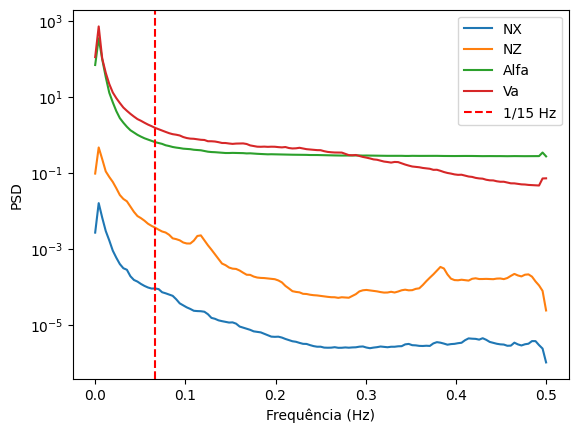

In [19]:
df = make_df('completo')

fs = 1.0  # Hz — taxa de amostragem
f_NX, Pxx_NX = welch(df['NX'].values, fs=fs, nperseg=256)
plt.semilogy(f_NX, Pxx_NX, label='NX')
plt.xlabel('Frequência (Hz)')
plt.ylabel('PSD')
plt.legend()

f_NZ, Pxx_NZ = welch(df['NZ'].values, fs=fs, nperseg=256)
plt.semilogy(f_NZ, Pxx_NZ, label='NZ')
plt.legend()

f_Alfa, Pxx_Alfa = welch(df['Alfa'].values, fs=fs, nperseg=256)
plt.semilogy(f_Alfa, Pxx_Alfa, label='Alfa')
plt.legend()

f_Va, Pxx_Va = welch(df['Va'].values, fs=fs, nperseg=256)
plt.semilogy(f_Va, Pxx_Va, label='Va')
plt.legend()

plt.axvline(1/15, color='r', linestyle='--', label='1/15 Hz')
plt.legend()

plt.show()

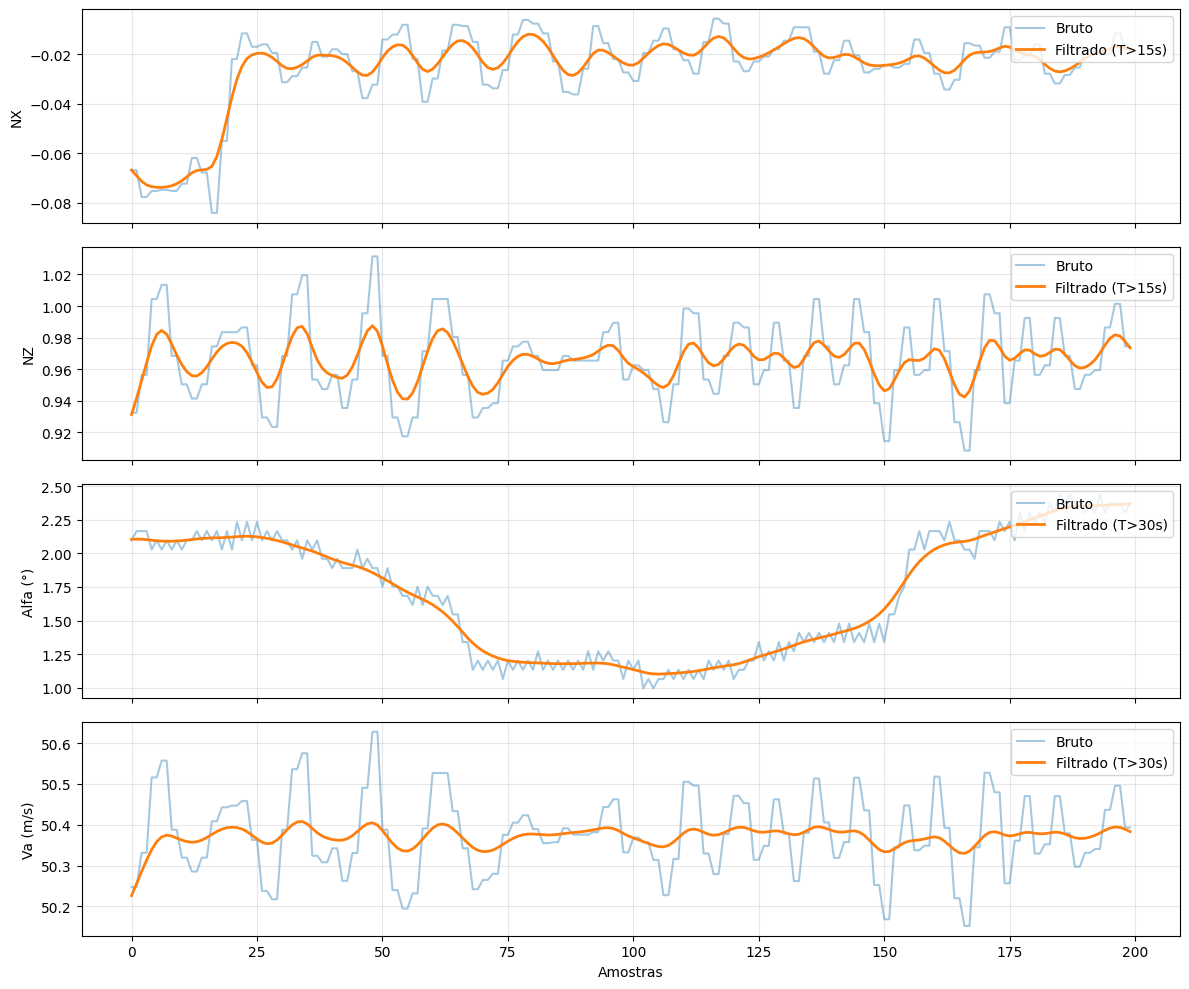

In [20]:
df = make_df('completo')

# Teste visual — escolha um segmento de manobra conhecido
seg = df.iloc[1000:1200]  # ajuste para um trecho interessante

fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)

for ax, col, period, label in zip(
    axes,
    ['NX', 'NZ', 'Alfa', 'Va'],
    [15,   15,   30,    30 ],
    ['NX', 'NZ', 'Alfa (°)', 'Va (m/s)']
):
    bruto = seg[col].values
    filtrado = butter_lowpass(bruto, period)
    ax.plot(bruto,    alpha=0.4, label='Bruto')
    ax.plot(filtrado, linewidth=2, label=f'Filtrado (T>{period}s)')
    ax.set_ylabel(label)
    ax.legend(loc='upper right')
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel('Amostras')
plt.tight_layout()
plt.show()

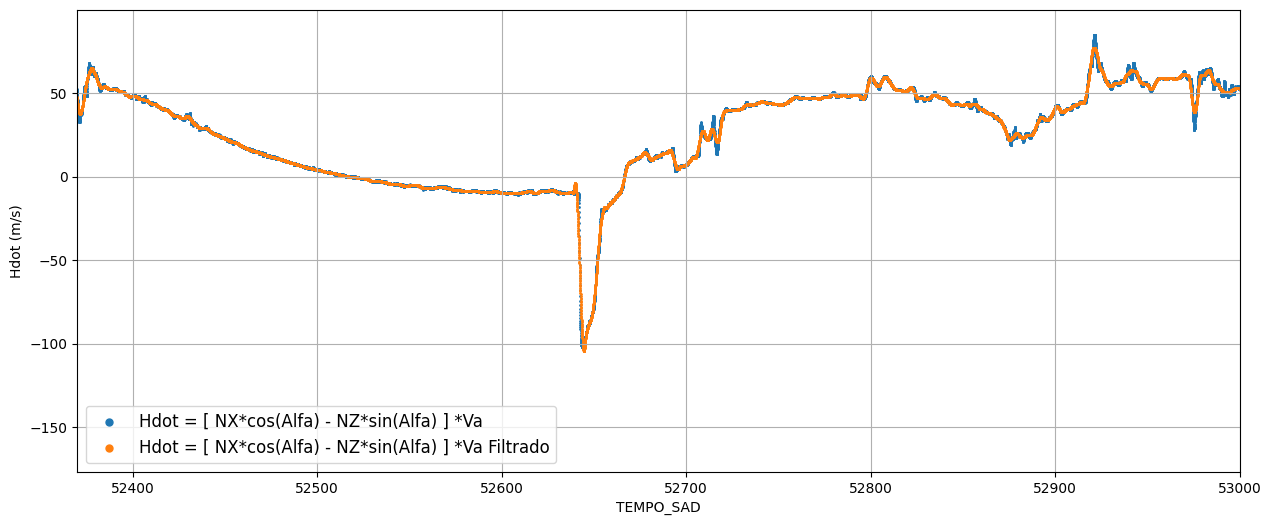

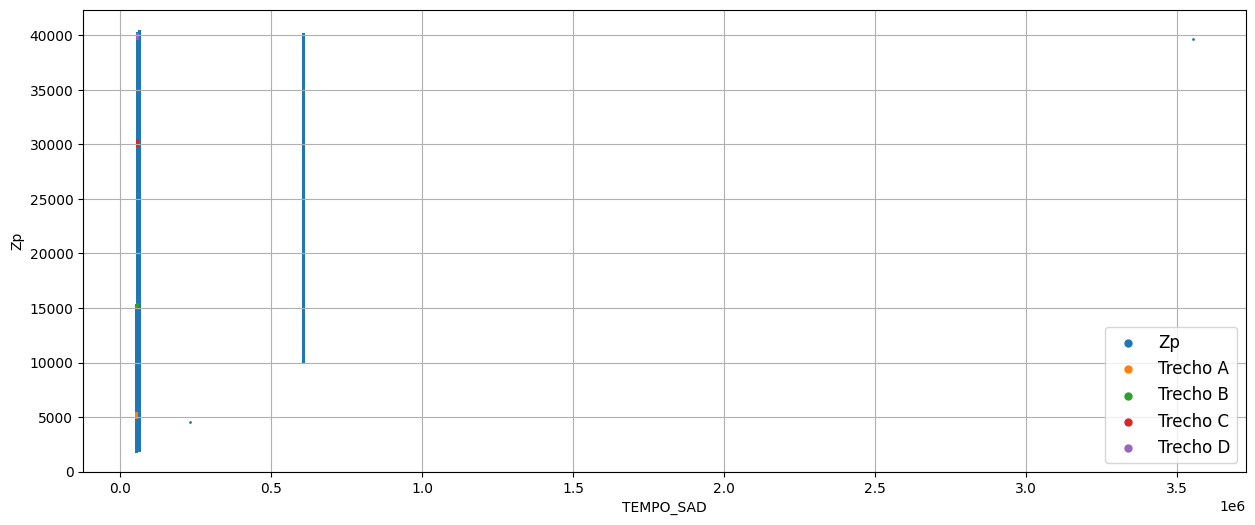

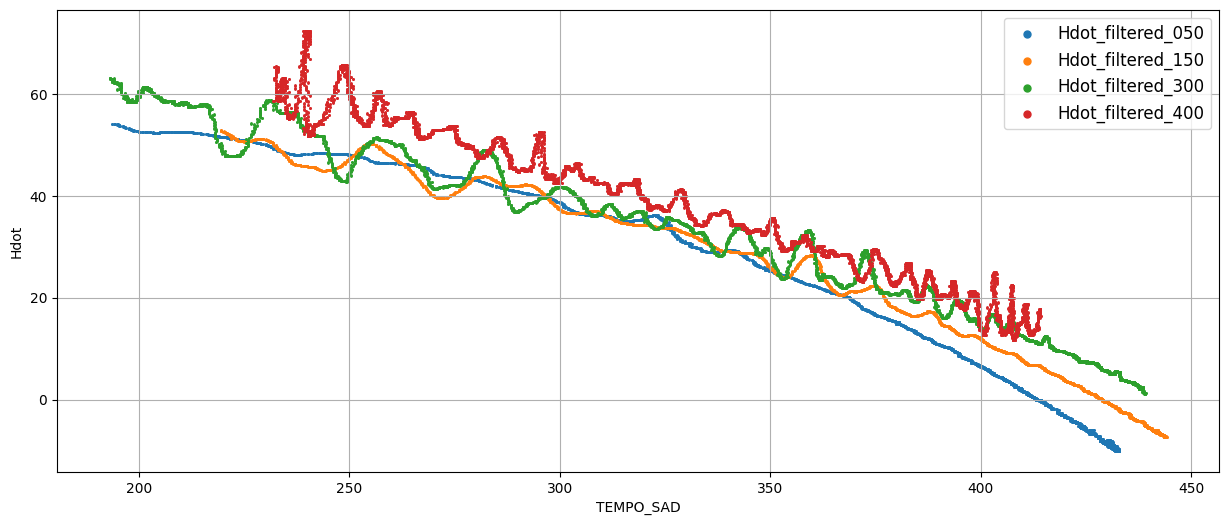

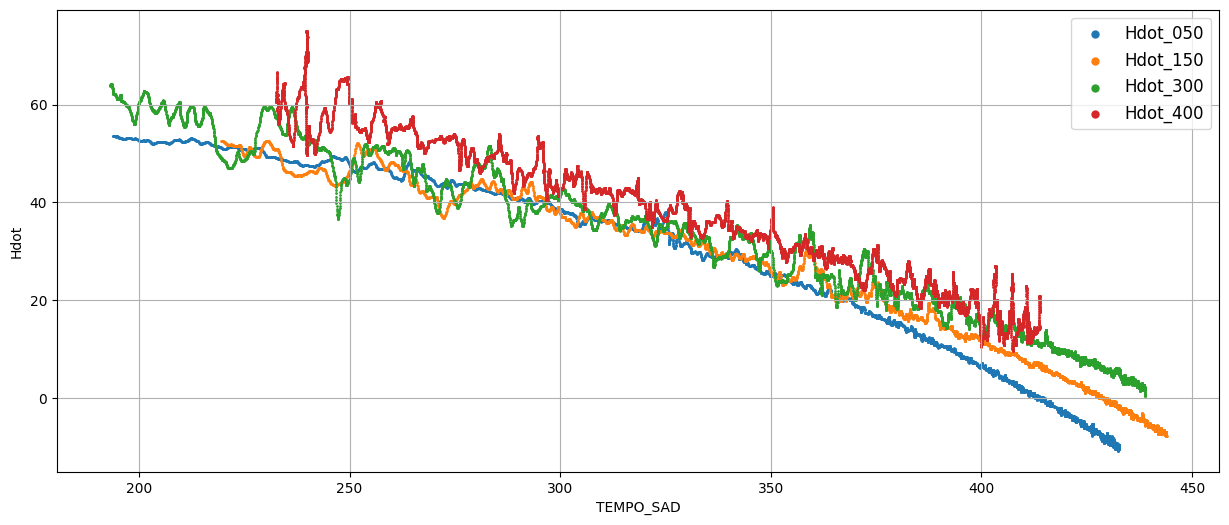

In [21]:
def analise_voo_completo():
    df = make_df('completo')

    g = 9.81

    t0_A = 52385
    t_A = 52634

    t0_B = 53000
    t_B = 53233

    t0_C = 53760
    t_C = 54060

    t0_D = 54750
    t_D = 55129

    t0 = 4e4
    t = df['TEMPO_SAD'].max()
    
    
    
    n=501
    grau=2
    # T = df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'TEMPO_SAD'].diff().mean() # Taxa de aquisição: aproximadamente 32 Hz, o que é consistente com os dados de tempo fornecidos
    T = 1/32

    df['Vdot'] = None
    df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'Vdot'] = savgol_filter(
        df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'Va']
        , window_length=n, polyorder=grau, deriv=1, delta=T)*0.5144

    df['hdot'] = None
    df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'hdot'] = savgol_filter(
        df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'Zp']
        , window_length=n, polyorder=grau, deriv=1, delta=T)*0.3048

    df['Hdot_2nd_approach'] = df['hdot'] + df['Va']*df['Vdot']/g

    n2 = 201
    grau2 = 2
    df['Hdot_filtered'] = None
    df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'Hdot_filtered'] = savgol_filter(
        df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'Hdot']
        , window_length=n2, polyorder=grau2, delta=T)

    plt.figure(figsize=(15, 6))
    eixo_x = 'TEMPO_SAD'
    plt.scatter(
        df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), eixo_x],
        df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'Hdot'],
        s=1, label='Hdot = [ NX*cos(Alfa) - NZ*sin(Alfa) ] *Va'
    )
    plt.scatter(
        df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), eixo_x],
        df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'Hdot_filtered'],
        s=1, label='Hdot = [ NX*cos(Alfa) - NZ*sin(Alfa) ] *Va Filtrado'
    )
    plt.xlabel(eixo_x)
    plt.ylabel('Hdot (m/s)')
    plt.grid()
    plt.legend(fontsize=12, markerscale=5)
    plt.xlim(52370,53000)
    # plt.ylim(-0.2, 1)
    plt.show()


    plt.figure(figsize=(15, 6))
    plt.scatter(
        df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'TEMPO_SAD'],
        df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'Zp'],
        s=1, label='Zp'
    )
    plt.scatter(
        df.loc[(df['TEMPO_SAD']>t0_A) & (df['TEMPO_SAD']<t_A), 'TEMPO_SAD'],
        df.loc[(df['TEMPO_SAD']>t0_A) & (df['TEMPO_SAD']<t_A), 'Zp'],
        s=1, label='Trecho A'
    )
    plt.scatter(
        df.loc[(df['TEMPO_SAD']>t0_B) & (df['TEMPO_SAD']<t_B), 'TEMPO_SAD'],
        df.loc[(df['TEMPO_SAD']>t0_B) & (df['TEMPO_SAD']<t_B), 'Zp'],
        s=1, label='Trecho B'
    )
    plt.scatter(
        df.loc[(df['TEMPO_SAD']>t0_C) & (df['TEMPO_SAD']<t_C), 'TEMPO_SAD'],
        df.loc[(df['TEMPO_SAD']>t0_C) & (df['TEMPO_SAD']<t_C), 'Zp'],
        s=1, label='Trecho C'
    )
    plt.scatter(
        df.loc[(df['TEMPO_SAD']>t0_D) & (df['TEMPO_SAD']<t_D), 'TEMPO_SAD'],
        df.loc[(df['TEMPO_SAD']>t0_D) & (df['TEMPO_SAD']<t_D), 'Zp'],
        s=1, label='Trecho D'
    )
    plt.xlabel('TEMPO_SAD')
    plt.ylabel('Zp')
    plt.grid()
    # plt.xlim(0, 50000)
    plt.legend(fontsize=12, markerscale=5)
    plt.show()


    plt.figure(figsize=(15, 6))
    plt.scatter(
        df.loc[(df['TEMPO_SAD']>t0_A) & (df['TEMPO_SAD']<t_A), 'Va'],
        df.loc[(df['TEMPO_SAD']>t0_A) & (df['TEMPO_SAD']<t_A), 'Hdot_filtered'],
        s=1, label='Hdot_filtered_050'
    )
    plt.scatter(
        df.loc[(df['TEMPO_SAD']>t0_B) & (df['TEMPO_SAD']<t_B), 'Va'],
        df.loc[(df['TEMPO_SAD']>t0_B) & (df['TEMPO_SAD']<t_B), 'Hdot_filtered'],
        s=1, label='Hdot_filtered_150'
    )
    plt.scatter(
        df.loc[(df['TEMPO_SAD']>t0_C) & (df['TEMPO_SAD']<t_C), 'Va'],
        df.loc[(df['TEMPO_SAD']>t0_C) & (df['TEMPO_SAD']<t_C), 'Hdot_filtered'],
        s=1, label='Hdot_filtered_300'
    )
    plt.scatter(
        df.loc[(df['TEMPO_SAD']>t0_D) & (df['TEMPO_SAD']<t_D), 'Va'],
        df.loc[(df['TEMPO_SAD']>t0_D) & (df['TEMPO_SAD']<t_D), 'Hdot_filtered'],
        s=1, label='Hdot_filtered_400'
    )
    plt.xlabel('TEMPO_SAD')
    plt.ylabel('Hdot')
    plt.grid()
    plt.legend(fontsize=12, markerscale=5)
    plt.show()

    plt.figure(figsize=(15, 6))
    plt.scatter(
        df.loc[(df['TEMPO_SAD']>t0_A) & (df['TEMPO_SAD']<t_A), 'Va_filtered'],
        df.loc[(df['TEMPO_SAD']>t0_A) & (df['TEMPO_SAD']<t_A), 'Hdot'],
        s=1, label='Hdot_050'
    )
    plt.scatter(
        df.loc[(df['TEMPO_SAD']>t0_B) & (df['TEMPO_SAD']<t_B), 'Va_filtered'],
        df.loc[(df['TEMPO_SAD']>t0_B) & (df['TEMPO_SAD']<t_B), 'Hdot'],
        s=1, label='Hdot_150'
    )
    plt.scatter(
        df.loc[(df['TEMPO_SAD']>t0_C) & (df['TEMPO_SAD']<t_C), 'Va_filtered'],
        df.loc[(df['TEMPO_SAD']>t0_C) & (df['TEMPO_SAD']<t_C), 'Hdot'],
        s=1, label='Hdot_300'
    )
    plt.scatter(
        df.loc[(df['TEMPO_SAD']>t0_D) & (df['TEMPO_SAD']<t_D), 'Va_filtered'],
        df.loc[(df['TEMPO_SAD']>t0_D) & (df['TEMPO_SAD']<t_D), 'Hdot'],
        s=1, label='Hdot_400'
    )
    plt.xlabel('TEMPO_SAD')
    plt.ylabel('Hdot')
    plt.grid()
    plt.legend(fontsize=12, markerscale=5)
    plt.show()
analise_voo_completo()

42493


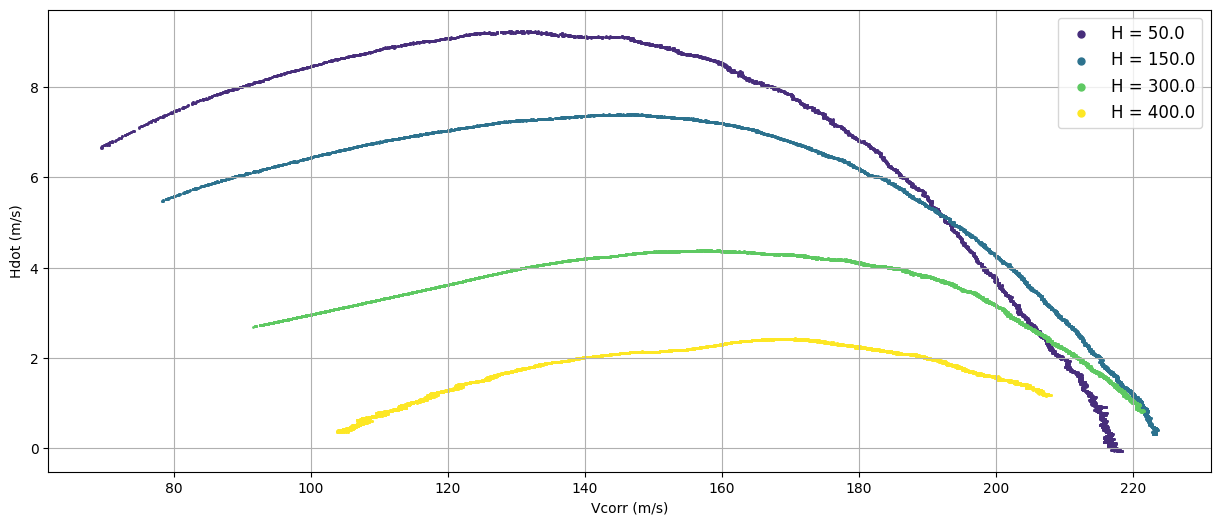

In [22]:
def analise_voo_aceleracao_nivelada():
    df = make_df('aceleracao_nivelada')
    print(len(df))
    
    plt.figure(figsize=(15, 6))
    eixo_x = 'Vcorr'
    
    for h, grupo in df.groupby('h'):
        plt.scatter(
            grupo[eixo_x],
            grupo['Hdot'],
            s=1, label=f'H = {h}', color=plt.cm.viridis(h/400)
        )
    
    plt.xlabel(eixo_x + ' (m/s)')
    plt.ylabel('Hdot (m/s)')
    plt.grid()
    plt.legend(fontsize=12, markerscale=5)
    plt.show()

analise_voo_aceleracao_nivelada()

In [23]:
def split_train_test_val(df):
    df['type'] = 'train'    
    df.loc[df['faixa_altitude'] == 'B', 'type'] = 'test'

    test_size = 0.2
    m = round((1-test_size)*len(df.loc[df['type'] == 'test']))
    val_indices = df.loc[df['type'] == 'test'].sample(n=m, random_state=42).index
    df.loc[val_indices, 'type'] = 'val'
    
    return df

In [24]:
def scale_data(df, features1, features2, targets):
    scaler_x1 = MinMaxScaler()
    scaler_x2 = MinMaxScaler()
    scaler_y  = MinMaxScaler()

    cols1 = features1
    cols2 = features2
    colsy = targets

    df[[p+'_scaled' for p in cols1]] = None
    df[[p+'_scaled' for p in cols2]] = None
    df[[p+'_scaled' for p in colsy]] = None

    for split, method in [('train','fit_transform'), ('test','transform'), ('val','transform')]:
        mask = df['type'] == split
        df.loc[mask, [p+'_scaled' for p in cols1]] = getattr(scaler_x1, method)(df.loc[mask, cols1])
        df.loc[mask, [p+'_scaled' for p in cols2]] = getattr(scaler_x2, method)(df.loc[mask, cols2])
        df.loc[mask, [p+'_scaled' for p in colsy]] = getattr(scaler_y,  method)(df.loc[mask, colsy])

    return df, scaler_x1, scaler_x2, scaler_y

In [25]:
def build_model(features1, features2, architecture={}, hyperparameters={}):
    """
    Constrói duas sub-redes paralelas cujas saídas Z1 e Z2
    são combinadas por subtração (Z1 - Z2) para produzir Y.

    Args:
        features1 (list): Features da entrada X1.
        features2 (list): Features da entrada X2.
        architecture (dict):
            - neurons       (int):   Neurônios por camada oculta.
            - camadas_ocultas (int): Número de camadas ocultas em cada sub-rede.
            - activation    (str):   Função de ativação (ex: 'relu').
            - dropout       (float): Taxa de dropout após cada camada oculta (0 = sem dropout).
        hyperparameters (dict):
            - optimizer     (str):   Nome do otimizador (ex: 'adam').
            - learning_rate (float): Taxa de aprendizado.
            - epochs        (int):   Épocas de treino (armazenado como atributo do modelo).
            - batch_size    (int):   Batch size (armazenado como atributo do modelo).
            - patience      (int):   Paciência para EarlyStopping (armazenado como atributo).
    """
    neurons          = architecture.get('neurons', 32)
    n_hidden         = architecture.get('camadas_ocultas', 2)
    activation       = architecture.get('activation', 'relu')
    dropout_rate     = architecture.get('dropout', 0.0)

    optimizer_name   = hyperparameters.get('optimizer', 'adam')
    learning_rate    = hyperparameters.get('learning_rate', 0.001)
    epochs           = hyperparameters.get('epochs', 100)
    batch_size       = hyperparameters.get('batch_size', 32)
    patience         = hyperparameters.get('patience', 3)

    def build_subnetwork(input_tensor, name_prefix):
        """Empilha n camadas ocultas Dense + Dropout opcional."""
        x = input_tensor
        for i in range(n_hidden):
            x = layers.Dense(
                neurons,
                activation=activation,
                name=f'{name_prefix}_hidden_{i+1}'
            )(x)
            if dropout_rate > 0:
                x = layers.Dropout(dropout_rate, name=f'{name_prefix}_dropout_{i+1}')(x)
        z = layers.Dense(1, name=f'{name_prefix}_output')(x)
        return z

    # --- Entradas ---
    input_x1 = layers.Input(shape=(len(features1),), name='Entrada_X1')
    input_x2 = layers.Input(shape=(len(features2),), name='Entrada_X2')

    # --- Sub-redes ---
    z1 = build_subnetwork(input_x1, name_prefix='NN1')
    z2 = build_subnetwork(input_x2, name_prefix='NN2')

    # --- Combinação e saída ---
    output = layers.Subtract(name='Saida_Y')([z1, z2])

    # --- Modelo ---
    model = Model(inputs=[input_x1, input_x2], outputs=output)

    # --- Otimizador com learning rate customizado ---
    optimizer = keras.optimizers.get({
        'class_name': optimizer_name,
        'config': {'learning_rate': learning_rate}
    })

    model.compile(optimizer=optimizer, loss='mse')

    # Armazena hiperparâmetros de treino como atributos para uso externo
    model.epochs     = epochs
    model.batch_size = batch_size
    model.patience   = patience

    return model

In [57]:
def train_model(df, features1, features2, targets, model, hyperparameters):

    features1_scaled = []
    for item in features1:
        features1_scaled.append(item + '_scaled')

    features2_scaled = []
    for item in features2:
        features2_scaled.append(item + '_scaled')

    targets_scaled = []
    for item in targets:
        targets_scaled.append(item + '_scaled')

    X1_train, X1_val = np.array(df.loc[df['type'] == 'train', features1_scaled]).astype(np.float32), np.array(df.loc[df['type'] == 'val', features1_scaled]).astype(np.float32)
    X2_train, X2_val = np.array(df.loc[df['type'] == 'train', features2_scaled]).astype(np.float32), np.array(df.loc[df['type'] == 'val', features2_scaled]).astype(np.float32)
    Y_train, Y_val = np.array(df.loc[df['type'] == 'train', targets_scaled]).astype(np.float32), np.array(df.loc[df['type'] == 'val', targets_scaled]).astype(np.float32)

    callback = keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=hyperparameters['patience'],
        restore_best_weights=True
    )

    print("Treinando modelo...")
    training_history = model.fit(
        [X1_train, X2_train], Y_train,
        epochs=hyperparameters['epochs'],
        batch_size=hyperparameters['batch_size'],
        callbacks=[callback],
        validation_data=([X1_val, X2_val], Y_val),
        verbose=1
    )
    joblib.dump(training_history, './trainHistoryDict.pkl')
    model.save('./model.keras')

    return model, training_history

In [56]:
def pipeline(tipo_dados, architecture, hyperparameters, features1, features2, targets, mode):
    df = make_df(tipo_dados)
    df = split_train_test_val(df)
    df, scaler_x1, scaler_x2, scaler_y = scale_data(df, features1, features2, targets)

    if mode == 'train':
        model = build_model(features1, features2, architecture, hyperparameters)
        model, training_history = train_model(df, features1, features2, targets, model, hyperparameters)
    elif mode == 'read':
        print('Carregando o modelo...')
        model, training_history = keras.models.load_model('./model.keras'), joblib.load('./trainHistoryDict.pkl')
    return df, scaler_x1, scaler_x2, scaler_y, model, training_history

In [28]:
def evaluate(model, df, features1, features2, targets, scaler_y, evaluated_set='test'):

    features1_scaled = [item + '_scaled' for item in features1]
    features2_scaled = [item + '_scaled' for item in features2]

    # Previsão sobre todo o dataframe
    X_all = [
        np.array(df[features1_scaled]).astype(np.float32),
        np.array(df[features2_scaled]).astype(np.float32)
    ]

    pred_scaled_all = model.predict(X_all)
    pred_all = scaler_y.inverse_transform(pred_scaled_all)

    for i, item in enumerate(targets):
        df[item + '_pred'] = pred_all[:, i]

    # Monta results somente com o subconjunto avaliado
    mask = df['type'] == evaluated_set

    pred = pred_all[mask.values]
    real = np.array(df.loc[mask, targets]).astype(np.float32)

    with np.errstate(divide='ignore', invalid='ignore'):
        erro = np.where(np.abs(real) > 1e-6, abs((pred - real) * 100 / real), np.nan)
    avg_error = np.nanmean(erro, axis=0).astype(np.float32)

    results = {
        'predicted': pred,
        'real': real,
        'rel_error': erro,
        'avg_error': avg_error
    }

    return results, df

In [49]:
def analyze (
        tipo_dados,
        features1,
        features2,
        targets,
        architecture={
            'neurons': 32,
            'camadas_ocultas': 3,
            'activation': 'relu',
            'dropout': 0.5
        },
        hyperparameters={
            'optimizer': 'adam',
            'learning_rate': 0.0001,
            'epochs': 60,
            'batch_size': 64,
            'patience': 4
        },
        # architecture={
        #     'neurons': 5,
        #     'camadas_ocultas': 1,
        #     'activation': 'relu',
        #     'dropout': 0
        # },
        # hyperparameters={
        #     'optimizer': 'adam',
        #     'learning_rate': 0.01,
        #     'epochs': 2,
        #     'batch_size': 64,
        #     'patience': 2
        # },
        evaluated_set='test',
        mode='train'
        ):
    df, scaler_x1, scaler_x2, scaler_y, model, training_history = pipeline(
        tipo_dados=tipo_dados,
        architecture=architecture,
        hyperparameters=hyperparameters,
        features1=features1,
        features2=features2,
        targets=targets,
        mode=mode
    )

    targets_names = targets[0]
    for i in range(1, len(targets)):
        targets_names += '_' + targets[i]

    results, df = evaluate(model, df, features1, features2, targets, scaler_y, evaluated_set)

    plt.plot(training_history.history['loss'])
    plt.plot(training_history.history['val_loss'])
    plt.title('Model Loss')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')
    plt.grid()
    plt.savefig(f'{targets_names}_approach_training.png')
    plt.show()

    _, axs = plt.subplots(
        2 * len(targets),
        1,
        sharex=True,
        # figsize=(12, 3 * len(targets)),
        constrained_layout=True
    )
    axs = axs.flatten()
    dot_size = 2

    for i, item in enumerate(targets):
        axs[2*i].set_title(f'Comparação de {item} Real vs. Predito')
        axs[2*i].scatter(df.loc[df['type'] == evaluated_set]['TEMPO_SAD'], df.loc[df['type']==evaluated_set][f'{item}'], dot_size, label=f'{item} Real')
        axs[2*i].scatter(df.loc[df['type'] == evaluated_set]['TEMPO_SAD'], df.loc[df['type']==evaluated_set][f'{item}_pred'], dot_size, label=f'{item} Predito')
        axs[2*i].legend()
        axs[2*i].grid()

        axs[2*i+1].set_title(f'Erro médio: {results["avg_error"][i]:.2f}%')
        axs[2*i+1].scatter(df.loc[df['type'] == evaluated_set]['TEMPO_SAD'], results["rel_error"][:,i], dot_size)
        axs[2*i+1].legend()
        axs[2*i+1].grid()
    plt.savefig(f'figures/{targets_names}_approach_results.png')
    plt.show()

    return df, scaler_x1, scaler_x2, scaler_y, model, training_history, results

Carregando o modelo...
18772/18772 ━━━━━━━━━━━━━━━━━━━━ 10s 542us/step


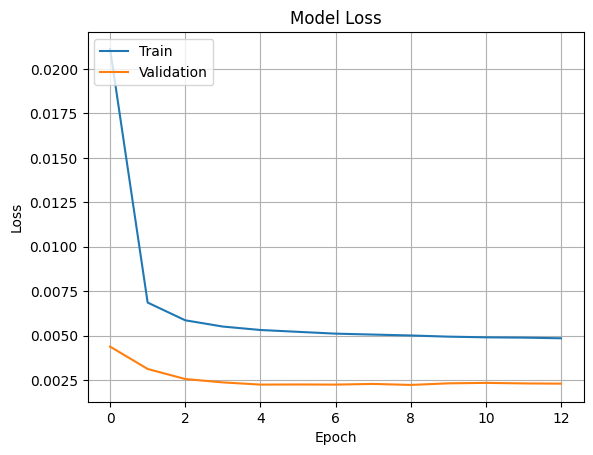

C:\Users\ymarc\AppData\Local\Temp\ipykernel_1548\901774151.py:80: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


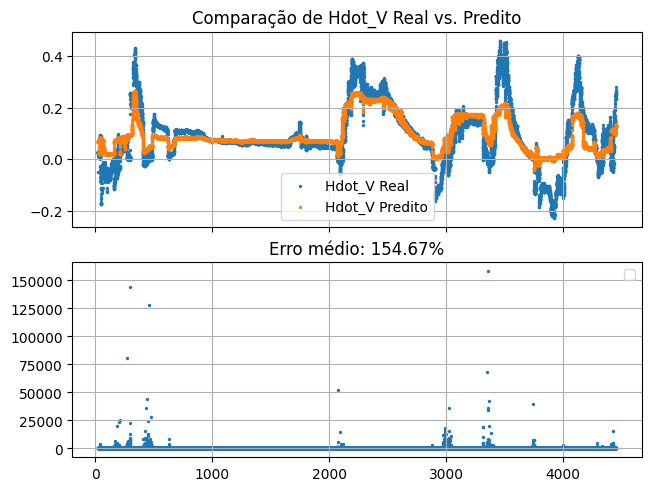

In [59]:
df, scaler_x1, scaler_x2, scaler_y, model, training_history, results = analyze(
    tipo_dados='completo',
    features1=['Mach', 'N1_over_sqrt_theta', 'W'],
    features2=['Mach', 'NZ_W_dlt', 'W'],
    targets=['Hdot_V'],
    mode='read'
)

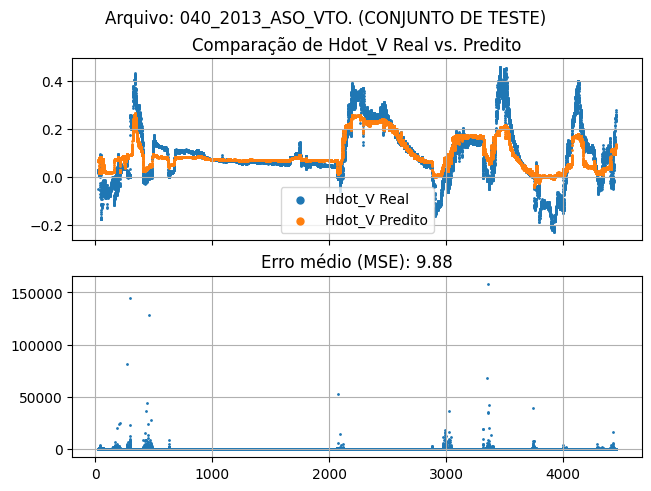

In [67]:
evaluated_set = 'test'
dot_size = 1

time_intervals = {
        '039_2013_VIN_FND': (5e4, 7e4),
        '040_2013_ASO_VTO': (0, 5e4),
        '041_2013_GEO_AIR': (0, 1e5),
        '042_2013_VAU_FTR': (0, 8e4)
    }

subset = df[df['type'] == evaluated_set]

for filename, grupo in subset.groupby('filename'):

    t0, t = time_intervals[filename]
    mask = (grupo['TEMPO_SAD'] > t0) & (grupo['TEMPO_SAD'] < t)
    grupo = grupo[mask]

    erro_medio_mse = np.nanmean(
        (grupo['Hdot_V_pred'] - grupo['Hdot_V'])**2 / grupo['Hdot_V'].abs() * 100
    )
    erro_relativo = (grupo['Hdot_V_pred'] - grupo['Hdot_V']) / grupo['Hdot_V'].abs() * 100

    _, axs = plt.subplots(2, 1, sharex=True, constrained_layout=True)
    _.suptitle(f'Arquivo: {filename}. (CONJUNTO DE TESTE)')

    axs[0].set_title('Comparação de Hdot_V Real vs. Predito')
    axs[0].scatter(grupo['TEMPO_SAD'], grupo['Hdot_V'],      s=dot_size, label='Hdot_V Real')
    axs[0].scatter(grupo['TEMPO_SAD'], grupo['Hdot_V_pred'], s=dot_size, label='Hdot_V Predito')
    axs[0].legend(markerscale=5)
    axs[0].grid()

    axs[1].set_title(f'Erro médio (MSE): {erro_medio_mse:.2f}')
    axs[1].scatter(grupo['TEMPO_SAD'], erro_relativo, s=dot_size)
    # axs[1].set_ylim(-100, 100)
    axs[1].grid()

    plt.show()

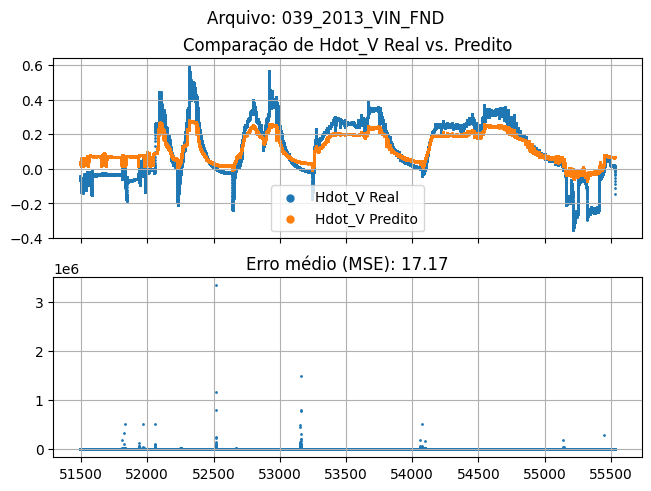

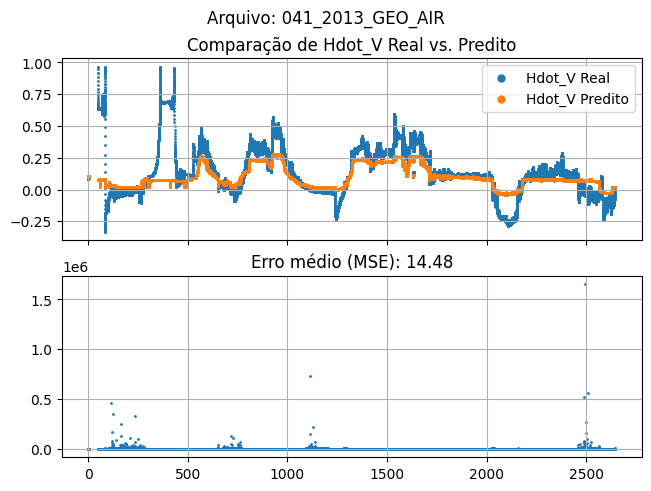

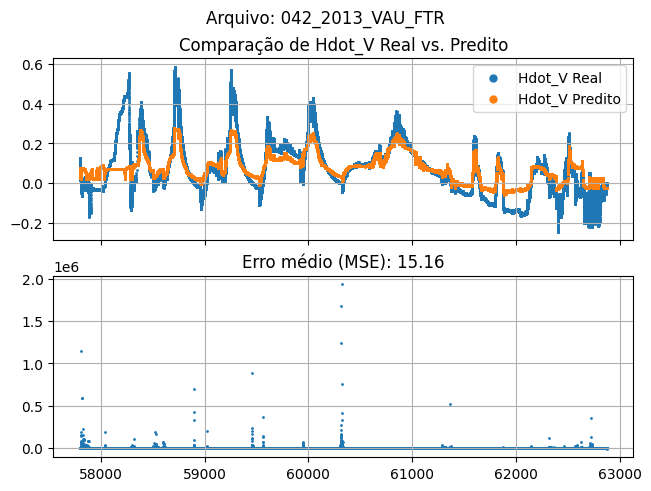

In [66]:
evaluated_set = 'train'
dot_size = 1

time_intervals = {
        '039_2013_VIN_FND': (5e4, 7e4),
        '040_2013_ASO_VTO': (0, 5e4),
        '041_2013_GEO_AIR': (0, 1e5),
        '042_2013_VAU_FTR': (0, 8e4)
    }

subset = df[df['type'] == evaluated_set]

for filename, grupo in subset.groupby('filename'):

    t0, t = time_intervals[filename]
    mask = (grupo['TEMPO_SAD'] > t0) & (grupo['TEMPO_SAD'] < t)
    grupo = grupo[mask]

    erro_medio_mse = np.nanmean(
        (grupo['Hdot_V_pred'] - grupo['Hdot_V'])**2 / grupo['Hdot_V'].abs() * 100
    )
    erro_relativo = (grupo['Hdot_V_pred'] - grupo['Hdot_V']) / grupo['Hdot_V'].abs() * 100

    _, axs = plt.subplots(2, 1, sharex=True, constrained_layout=True)
    _.suptitle(f'Arquivo: {filename}')

    axs[0].set_title('Comparação de Hdot_V Real vs. Predito')
    axs[0].scatter(grupo['TEMPO_SAD'], grupo['Hdot_V'],      s=dot_size, label='Hdot_V Real')
    axs[0].scatter(grupo['TEMPO_SAD'], grupo['Hdot_V_pred'], s=dot_size, label='Hdot_V Predito')
    axs[0].legend(markerscale=5)
    axs[0].grid()

    axs[1].set_title(f'Erro médio (MSE): {erro_medio_mse:.2f}')
    axs[1].scatter(grupo['TEMPO_SAD'], erro_relativo, s=dot_size)
    # axs[1].set_ylim(-100, 100)
    axs[1].grid()

    plt.show()

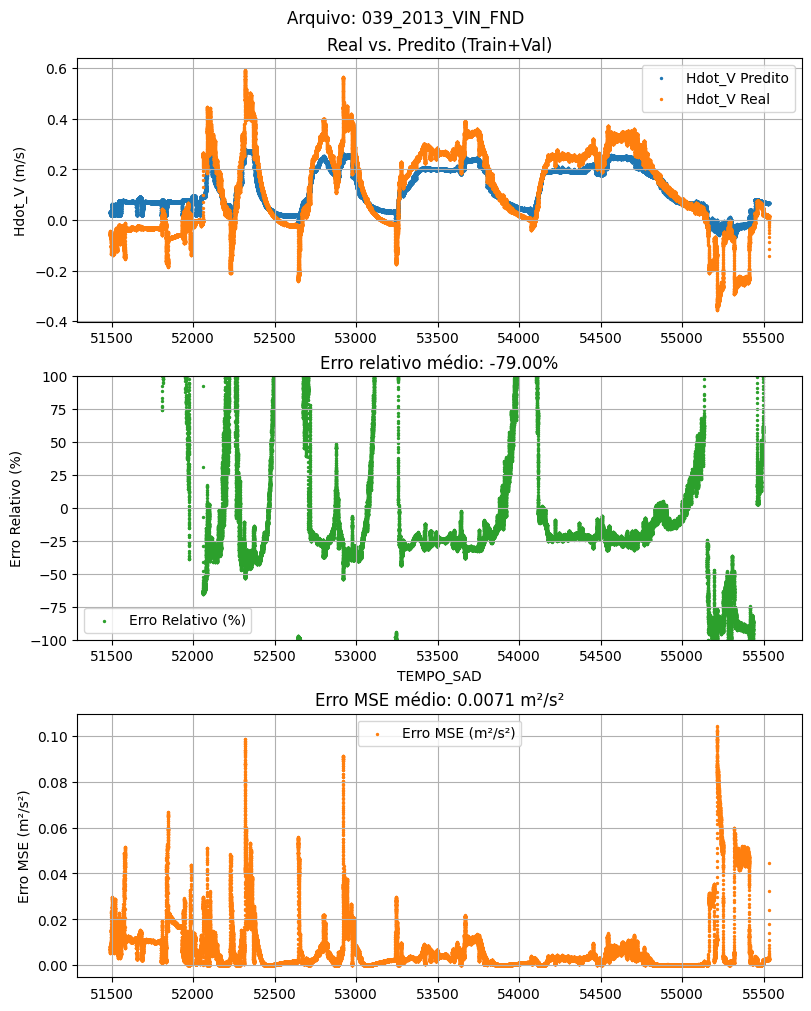

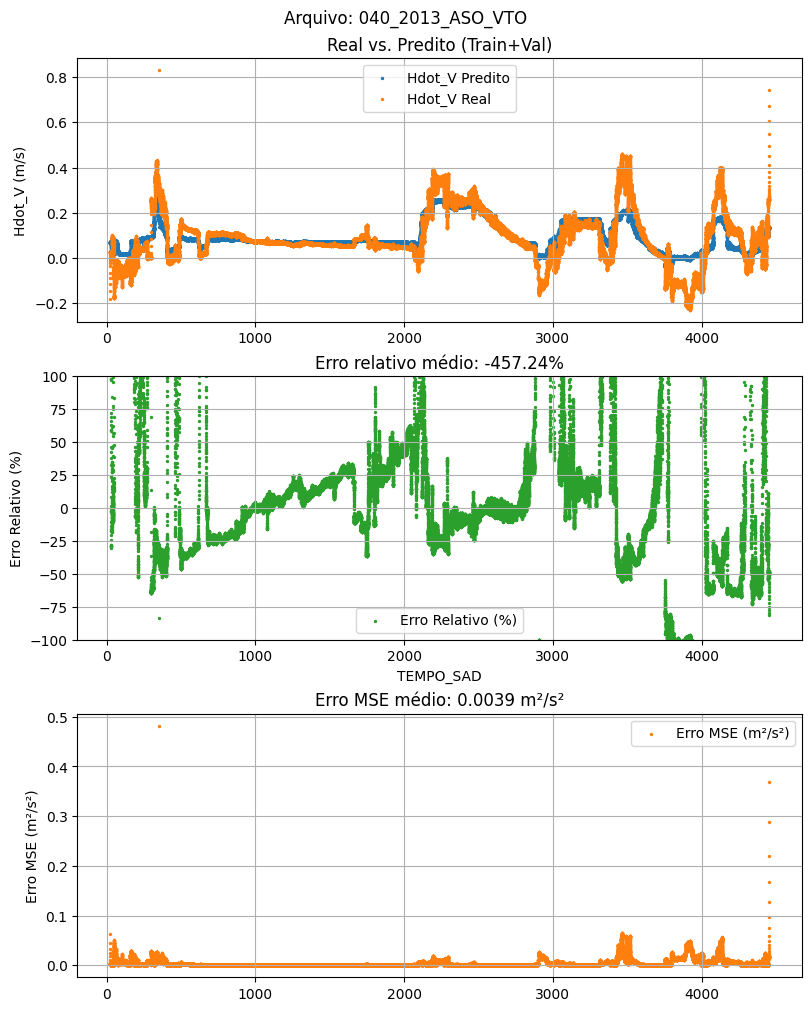

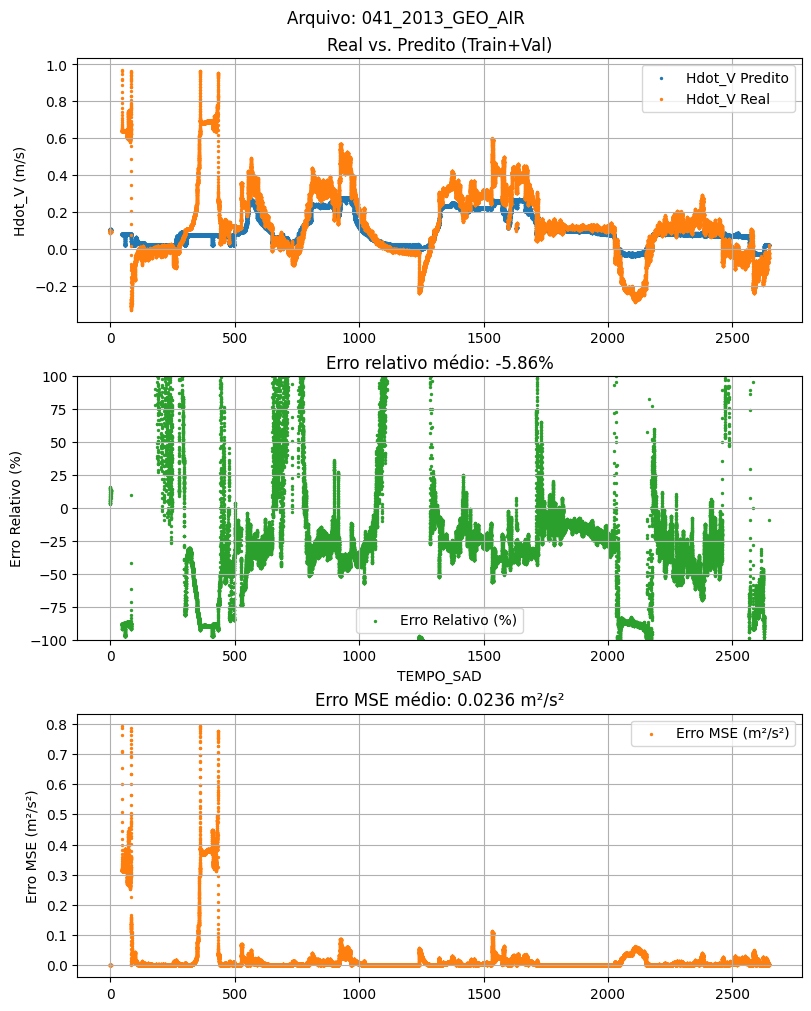

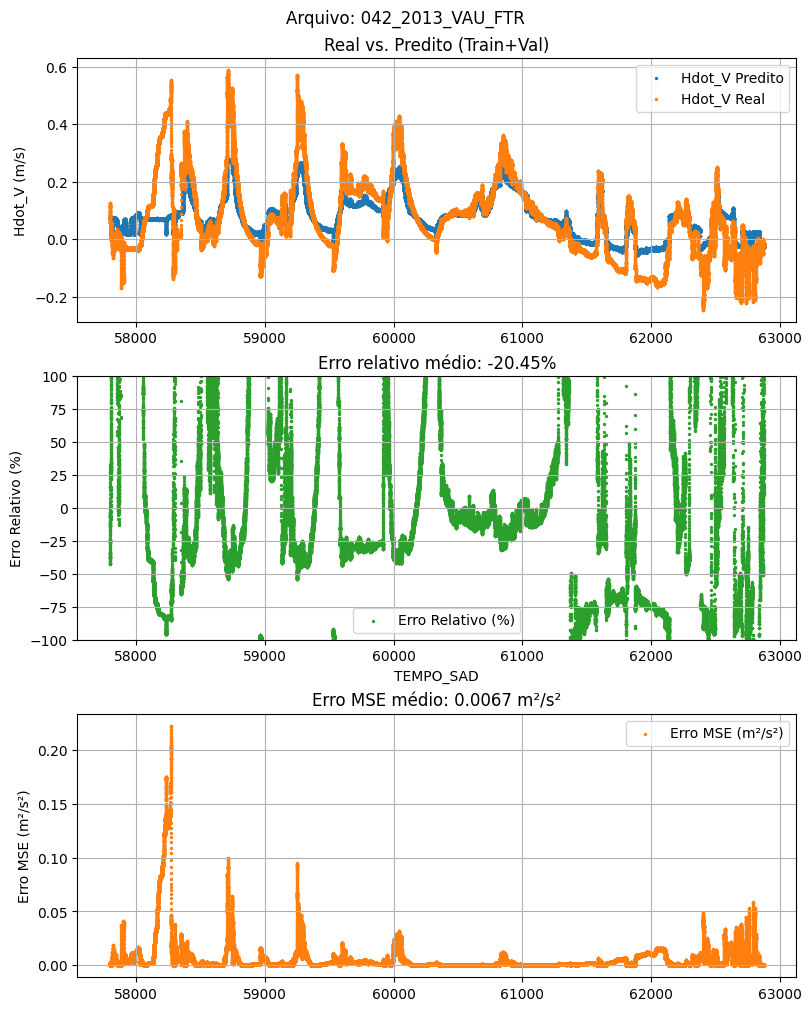

In [61]:
train_val = df[df['type'].isin(['train', 'val'])]
time_intervals = {
        '039_2013_VIN_FND': (5e4, 7e4),
        '040_2013_ASO_VTO': (0, 5e4),
        '041_2013_GEO_AIR': (0, 1e5),
        # '041_2013_GEO_AIR': (5e5, 8e5),
        '042_2013_VAU_FTR': (0, 8e4)
    }

for filename, grupo in train_val.groupby('filename'):
    t0, t = time_intervals[filename]

    grupo['erro_mse'] = (grupo['Hdot_V_pred'] - grupo['Hdot_V']) ** 2
    grupo['erro_relativo'] = (grupo['Hdot_V_pred'] - grupo['Hdot_V']) / grupo['Hdot_V'] * 100

    fig, axes = plt.subplots(3, 1, figsize=(8, 10), constrained_layout=True)
    fig.suptitle(f'Arquivo: {filename}', fontsize=12)

    # Predito vs. Real
    axes[0].scatter(grupo.loc[grupo['TEMPO_SAD'].between(t0, t), 'TEMPO_SAD'], grupo.loc[grupo['TEMPO_SAD'].between(t0, t), 'Hdot_V_pred'], label='Hdot_V Predito', s=2)
    axes[0].scatter(grupo.loc[grupo['TEMPO_SAD'].between(t0, t), 'TEMPO_SAD'], grupo.loc[grupo['TEMPO_SAD'].between(t0, t), 'Hdot_V'],      label='Hdot_V Real',    s=2)
    axes[0].set_ylabel('Hdot_V (m/s)')
    axes[0].set_title('Real vs. Predito (Train+Val)')
    axes[0].legend(markerscale=1)
    axes[0].grid()

    # Erro Relativo
    axes[1].scatter(grupo.loc[grupo['TEMPO_SAD'].between(t0, t), 'TEMPO_SAD'], grupo.loc[grupo['TEMPO_SAD'].between(t0, t), 'erro_relativo'], label='Erro Relativo (%)', s=2, color='tab:green')
    axes[1].set_ylabel('Erro Relativo (%)')
    axes[1].set_xlabel('TEMPO_SAD')
    axes[1].set_title('Erro relativo médio: {:.2f}%'.format(np.nanmean(grupo.loc[grupo['TEMPO_SAD'].between(t0, t), 'erro_relativo'])))
    axes[1].set_ylim(-100, 100)
    axes[1].legend(markerscale=1)
    axes[1].grid()

    # Erro MSE
    axes[2].scatter(grupo.loc[grupo['TEMPO_SAD'].between(t0, t), 'TEMPO_SAD'], grupo.loc[grupo['TEMPO_SAD'].between(t0, t), 'erro_mse'], label='Erro MSE (m²/s²)', s=2, color='tab:orange')
    axes[2].set_ylabel('Erro MSE (m²/s²)')
    axes[2].set_title('Erro MSE médio: {:.4f} m²/s²'.format(np.nanmean(grupo.loc[grupo['TEMPO_SAD'].between(t0, t), 'erro_mse'])))
    axes[2].legend(markerscale=1)
    axes[2].grid()

    plt.show()

In [62]:
# Modelo que expõe Z1 e Z2 além da saída final
extractor = keras.Model(
    inputs=model.inputs,
    outputs=[
        model.get_layer('NN1_output').output,  # Z1
        model.get_layer('NN2_output').output,  # Z2
        model.output                           # Y (Z1 - Z2)
    ]
)

In [63]:
features1 = ['Mach', 'N1_over_sqrt_theta', 'W']
features2 = ['Mach', 'NZ_W_dlt', 'W']

features1_scaled = [f + '_scaled' for f in features1]
features2_scaled = [f + '_scaled' for f in features2]

X1_all = np.array(df[features1_scaled]).astype(np.float32)
X2_all = np.array(df[features2_scaled]).astype(np.float32)

z1_vals, z2_vals, y_vals = extractor.predict([X1_all, X2_all])

# Adiciona ao DataFrame (ainda em escala normalizada)
df['Z1_scaled'] = z1_vals.flatten()
df['Z2_scaled'] = z2_vals.flatten()

18772/18772 ━━━━━━━━━━━━━━━━━━━━ 10s 544us/step


In [64]:
df['Z1'] = scaler_y.inverse_transform(z1_vals).flatten()
df['Z2'] = scaler_y.inverse_transform(z2_vals).flatten()

In [65]:
# Z1 - Z2 deve bater com a predição Y (na escala normalizada)
assert np.allclose(z1_vals - z2_vals, y_vals, atol=1e-5), "Divergência inesperada!"

# Visualização rápida
print(df[['Z1', 'Z2', 'Hdot_V_pred']].describe())

                  Z1             Z2    Hdot_V_pred
count  600683.000000  600683.000000  600683.000000
mean       -0.124302      -0.572125       0.093045
std         0.035125       0.047980       0.074327
min        -0.184758      -0.685898      -0.068666
25%        -0.139694      -0.598529       0.043689
50%        -0.120595      -0.555564       0.075830
75%        -0.105260      -0.542114       0.136254
max         0.030158      -0.470870       0.279342


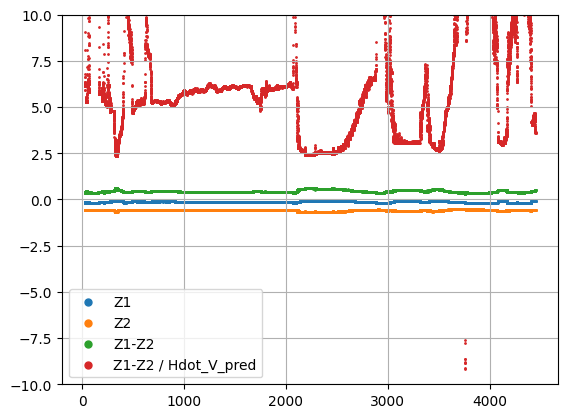

In [78]:
evaluated_set = 'test'
dot_size = 1

time_intervals = {
        '039_2013_VIN_FND': (5e4, 7e4),
        '040_2013_ASO_VTO': (0, 5e4),
        '041_2013_GEO_AIR': (0, 1e5),
        '042_2013_VAU_FTR': (0, 8e4)
    }

subset = df[df['type'] == evaluated_set]

for filename, grupo in subset.groupby('filename'):

    t0, t = time_intervals[filename]
    mask = (grupo['TEMPO_SAD'] > t0) & (grupo['TEMPO_SAD'] < t)
    grupo = grupo[mask]

    erro_medio_mse = np.nanmean(
        (grupo['Hdot_V_pred'] - grupo['Hdot_V'])**2 / grupo['Hdot_V'].abs() * 100
    )
    erro_relativo = (grupo['Hdot_V_pred'] - grupo['Hdot_V']) / grupo['Hdot_V'].abs() * 100

    plt.scatter(grupo['TEMPO_SAD'], grupo['Z1'], s=dot_size, label='Z1')
    plt.scatter(grupo['TEMPO_SAD'], grupo['Z2'], s=dot_size, label='Z2')
    plt.scatter(grupo['TEMPO_SAD'], (grupo['Z1'] - grupo['Z2']), s=dot_size, label='Z1-Z2')
    plt.scatter(grupo['TEMPO_SAD'], (grupo['Z1'] - grupo['Z2'])/grupo['Hdot_V_pred'], s=dot_size, label='Z1-Z2 / Hdot_V_pred')
    plt.legend(markerscale=5)
    plt.ylim(-10,10)
    plt.grid()

    plt.show()

# Grid Search:

In [52]:
def model_constructor_grid_search(features1, features2, targets, neurons, optimizer, learning_rate, batch_size, epochs, activation):
    return build_model(
        features1=features1,
        features2=features2,
        targets=targets,
        architecture={
            'neurons': neurons,
            'camadas_ocultas': 2,
            'activation': activation,
            'dropout': 0.5
        },
        hyperparameters={
            'optimizer': optimizer,
            'learning_rate': learning_rate,
            'epochs': epochs,
            'batch_size': batch_size,
            'patience': 3
        }
    )

In [ ]:
features1_scaled = [f + '_scaled' for f in ['Mach', 'N1_over_sqrt_theta', 'W', 'Va']]
features2_scaled = [f + '_scaled' for f in ['Mach', 'CL', 'W', 'Va']]
targets_scaled   = ['Hdot_scaled']

split_idx = len(features1_scaled)  # índice de corte no array concatenado

def model_constructor_grid_search(neurons, optimizer, learning_rate,
                                   batch_size, epochs, activation):
    """
    KerasRegressor passa X como array único — separamos X1 e X2
    pelo split_idx definido no escopo externo.
    A separação real acontece dentro do Keras via Lambda.
    """

    n1 = len(features1_scaled)
    n2 = len(features2_scaled)

    # Entrada única concatenada (o que o GridSearchCV enxerga)
    input_combined = layers.Input(shape=(n1 + n2,), name='Entrada_combinada')

    # Separação interna
    input_x1 = layers.Lambda(lambda x: x[:, :n1],    name='Split_X1')(input_combined)
    input_x2 = layers.Lambda(lambda x: x[:, n1:],    name='Split_X2')(input_combined)

    def subnetwork(tensor, prefix, camadas_ocultas=2):
        x = tensor
        for i in range(camadas_ocultas):
            x = layers.Dense(neurons, activation=activation,
                             name=f'{prefix}_hidden_{i+1}')(x)
            x = layers.Dropout(0.5, name=f'{prefix}_dropout_{i+1}')(x)
        return layers.Dense(1, name=f'{prefix}_output')(x)

    z1 = subnetwork(input_x1, 'NN1')
    z2 = subnetwork(input_x2, 'NN2')

    output = layers.Subtract(name='Saida_Y')([z1, z2])
    model  = Model(inputs=input_combined, outputs=output)

    opt = keras.optimizers.get({
        'class_name': optimizer,
        'config': {'learning_rate': learning_rate}
    })
    model.compile(optimizer=opt, loss='mse')
    return model


model_wrapper = KerasRegressor(
    model=model_constructor_grid_search,
    verbose=1
)

param_grid = {
    'model__neurons':        [60, 80, 100, 120, 150],
    'model__optimizer':      ['adam'],
    'model__activation':     ['relu', 'tanh', 'sigmoid'],  # corrigido
    'model__learning_rate':  [0.001, 0.0001, 0.00001],
    'model__batch_size':     [32, 64, 128, 256],
    'model__epochs':         [80, 100, 120, 140],
}

X1_train_s = np.array(df.loc[df['type'] == 'train', features1_scaled]).astype(np.float32)
X2_train_s = np.array(df.loc[df['type'] == 'train', features2_scaled]).astype(np.float32)
Y_train_s  = np.array(df.loc[df['type'] == 'train', targets_scaled]).astype(np.float32)

# Concatena X1 e X2 — GridSearchCV aceita array único
X_train_s = np.hstack([X1_train_s, X2_train_s])

grid = GridSearchCV(
    model_wrapper,
    param_grid=param_grid,
    scoring='neg_mean_absolute_error',
    cv=3,
    n_jobs=-1
)

grid_result = grid.fit(X_train_s, Y_train_s)

# grid_result.append(...) não existe — para salvar os resultados:
import pandas as pd
results_df = pd.DataFrame(grid_result.cv_results_)
print("Melhores parâmetros:", grid_result.best_params_)
print("Melhor MAE:         ", -grid_result.best_score_)

c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Melhores parâmetros: {'model__activation': 'tanh', 'model__batch_size': 256, 'model__epochs': 140, 'model__learning_rate': 0.001, 'model__neurons': 150, 'model__optimizer': 'adam'}
Melhor MAE:          0.10863187288244565


23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


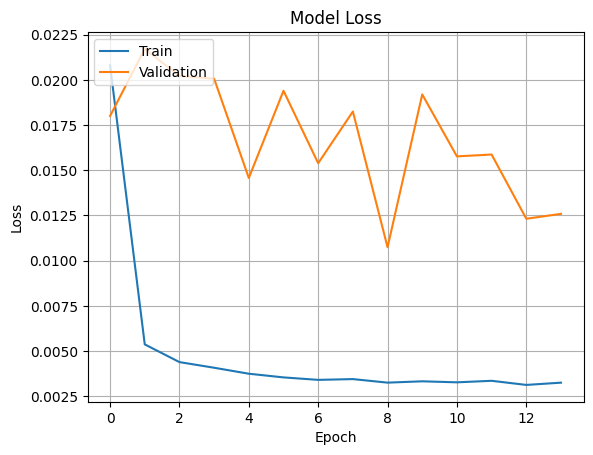

C:\Users\ymarc\AppData\Local\Temp\ipykernel_7756\242009600.py:64: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


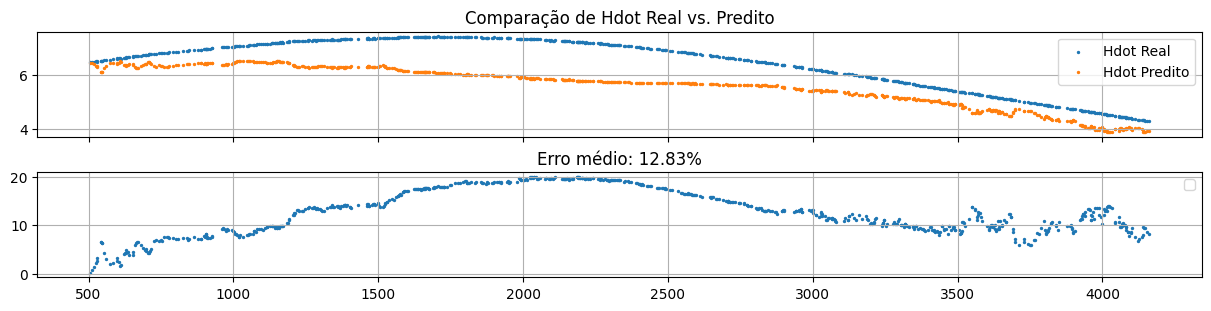

Erro máximo: 19.969042


In [199]:
df, scaler_x1, scaler_x2, scaler_y, model, training_history, results = analyze(
    tipo_dados='aceleracao_nivelada',
    features1=['T', 'W', 'Vcorr'],
    features2=['CD', 'W', 'CL', 'Vcorr'],
    targets=['Hdot'],
    architecture={
        'neurons': 50,
        'camadas_ocultas': 1,
        'activation': 'relu',
        'dropout': 0.5
    },
    hyperparameters={
        'optimizer': 'adam',
        'learning_rate': 0.001,
        'epochs': 50,
        'batch_size': 32,
        'patience': 5
    }
)
print("Erro máximo:", np.nanmax(results["rel_error"]))